In [1]:
from collections import defaultdict
from pathlib import Path

import colorcet as cc
import equinox as eqx
import jax
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from dynamical_systems.analysis.jacobian import jacobian
from dynamical_systems.continuous import Lorenz63, Lorenz96
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamical_systems.transforms import TransformedODE
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from dynamics_discovery.metrics.error import relative_error_norm
from dynamics_discovery.models import NeuralODE
from einops import rearrange
from matplotlib_utils.plots import plot_violin
from tqdm import tqdm


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)


EXP_TYPES_ALL = (
    "vanilla",
    "neighborhood",
    "efficient_neighborhood",
    "dyslim",
    "dyslim_neigh",
)
EXP_TYPES = (
    "efficient_neighborhood",
    "vanilla",
    # "neighborhood",
    "dyslim",
    # "dyslim_neigh",
)

COLOR_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            cc.cm.glasbey_dark(45),
            cc.cm.glasbey_dark(0),
            cc.cm.glasbey_dark(64),
            cc.cm.glasbey_dark(46),
            cc.cm.glasbey_dark(91),
        ),
    )
)
LABEL_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            "Vanilla",
            "Neighborhood (Ours)",
            "Neighborhood (Ours)",
            "DySLIM (ICML 2024)",
            "DySLIM - Neighborhood",
        ),
    )
)

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

ODE_LABEL_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6D)",
    "lorenz96_18d": "Lorenz96 (18D)",
    "lorenz96_54d": "Lorenz96 (54D)",
}

In [8]:
def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if exp_type == "efficient_neighborhood":
        loaddir = rootdir / dataset_name / exp_type / "smaller_radius/best"
        model_path_template = f"*_noise={noise}_key={key}*"
        model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_test_dataset(dataset_name: str, rootdir=Path("../../data/take3")):
    standardizer = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_train.hdf5"
    ).standardize()[1]
    dataset_test = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_test.hdf5"
    ).apply_transform(standardizer)
    return dataset_test, standardizer

In [3]:
def calculate_log_relative_jacobian_errors(
    dataset_name: str,
    exp_types=("efficient_neighborhood", "vanilla", "dyslim"),
    noises=(0.01, 0.05, 0.1),
    keys=(0, 10, 20),
):
    dataset_test, transform = load_test_dataset(dataset_name)
    u_data = rearrange(dataset_test.u, "B T C -> (B T) C")

    jacobian_batch = eqx.filter_vmap(jacobian, in_axes=(None, None, 0))
    jac_true = jacobian_batch(
        TransformedODE(ODE_DICT[dataset_name], transform), 0.0, u_data
    )

    @eqx.filter_jit
    def compute_jac_err(model):
        jac_pred = jacobian_batch(model, 0.0, u_data)
        return relative_error_norm(jac_pred, jac_true, axis=(-2, -1))

    jac_logerr_dict = defaultdict(list)
    for exp_type in tqdm(exp_types):
        jac_logerr_dict[exp_type] = [
            [
                np.log10(
                    compute_jac_err(
                        load_experiment(
                            dataset_name,
                            exp_type,
                            k,
                            n,
                        )
                    )
                )
                for k in keys
            ]
            for n in noises
        ]
    return jac_logerr_dict


def calculate_log_relative_rhs_errors(
    dataset_name: str,
    exp_types=("efficient_neighborhood", "vanilla", "dyslim"),
    noises=(0.01, 0.05, 0.1),
    keys=(0, 10, 20),
):
    dataset_test, transform = load_test_dataset(dataset_name)
    u_data = rearrange(dataset_test.u, "B T C -> (B T) C")

    rhs_true = eqx.filter_vmap(
        TransformedODE(ODE_DICT[dataset_name], transform).rhs, in_axes=(None, 0)
    )(0.0, u_data)

    @eqx.filter_jit
    def compute_rhs_err(model):
        rhs_pred = eqx.filter_vmap(model.rhs, in_axes=(None, 0))(0.0, u_data)
        return relative_error_norm(rhs_pred, rhs_true, axis=(-1,))

    rhs_logerr_dict = defaultdict(list)
    for exp_type in tqdm(exp_types):
        rhs_logerr_dict[exp_type] = [
            [
                np.log10(
                    compute_rhs_err(
                        load_experiment(
                            dataset_name,
                            exp_type,
                            k,
                            n,
                        )
                    )
                )
                for k in keys
            ]
            for n in noises
        ]
    return rhs_logerr_dict

In [4]:
def rhs_and_jac_error_vs_noise_figure(
    dataset_name: str,
    exp_types=("efficient_neighborhood", "vanilla", "dyslim"),
    noises=(0.01, 0.05, 0.1),
    keys=(0, 10, 20),
):
    jac_logerr_dict_all = calculate_log_relative_jacobian_errors(
        dataset_name, exp_types, noises, keys
    )
    rhs_logerr_dict_all = calculate_log_relative_rhs_errors(
        dataset_name, exp_types, noises, keys
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(4, 6),
        constrained_layout=True,
        sharex=True,
        gridspec_kw={"hspace": 0.05},
    )
    with plt.rc_context():
        plt.rcParams["font.size"] = 14
        for i in range(len(noises)):
            for exp_type in EXP_TYPES:
                side = "low" if exp_type == "efficient_neighborhood" else "high"
                plot_violin(
                    axes[0],
                    rhs_logerr_dict_all[exp_type][i],
                    positions=[i] * len(keys),
                    facecolor="none",
                    edgecolor=COLOR_DICT[exp_type],
                    linewidth=2.0,
                    alpha=0.8,
                    side=side,
                    showextrema=False,
                    showmeans=True,
                )
                plot_violin(
                    axes[1],
                    jac_logerr_dict_all[exp_type][i],
                    positions=[i] * len(keys),
                    facecolor="none",
                    edgecolor=COLOR_DICT[exp_type],
                    linewidth=2.0,
                    alpha=0.8,
                    side=side,
                    showextrema=False,
                    showmeans=True,
                )

        for ax, yname in zip(
            axes, ("log(Rel. Vector Field Error) (↓)", "log(Rel. Jacobian Error) (↓)")
        ):
            ax.set_ylabel(yname)
        axes[-1].set_xticks(list(range(len(noises))), noises)
        axes[-1].set_xlabel("Noise (%)")
    fig.align_ylabels()
    return fig

100%|██████████| 3/3 [00:00<00:00,  6.37it/s]


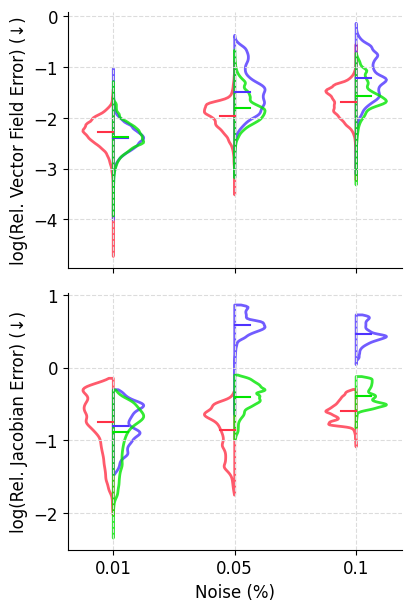

In [12]:
fig = rhs_and_jac_error_vs_noise_figure("lorenz63", keys=(0,))

In [6]:
def jac_error_across_datasets_figure(
    dataset_names: list[str],
    exp_types=("efficient_neighborhood", "vanilla", "dyslim"),
    noises=(0.01, 0.05, 0.1),
    keys=(0, 10, 20),
):
    fig, axes = plt.subplots(
        1,
        len(dataset_names),
        figsize=(12, 3),
        constrained_layout=True,
        sharex=True,
    )
    with plt.rc_context():
        plt.rcParams["font.size"] = 14
        for dataset, ax in zip(dataset_names, axes):
            jac_err_dict = calculate_log_relative_jacobian_errors(
                dataset, exp_types, noises, keys
            )

            for i in range(len(noises)):
                for exp_type in EXP_TYPES:
                    side = "low" if exp_type == "efficient_neighborhood" else "high"
                    plot_violin(
                        ax,
                        jac_err_dict[exp_type][i],
                        positions=[i] * len(keys),
                        facecolor="none",
                        edgecolor=COLOR_DICT[exp_type],
                        linewidth=2.0,
                        alpha=0.8,
                        side=side,
                        showextrema=False,
                        showmeans=True,
                    )
            ax.set_xticks(list(range(len(noises))), noises)
            ax.set_title(ODE_LABEL_DICT[dataset])
        fig.supxlabel("Noise (%)", fontsize="medium")
        axes[0].set_ylabel("log(Rel. Jacobian Error) (↓)")

        labels = [
            (mpatches.Patch(color=COLOR_DICT[e]), LABEL_DICT[e]) for e in exp_types
        ]
        fig.legend(*zip(*labels), loc="outside center right", fontsize="small")
    return fig

In [ ]:
fig2 = jac_error_across_datasets_figure(
    ["lorenz96_6d", "lorenz96_18d", "lorenz96_54d"], keys=(0,)
)

100%|██████████| 3/3 [00:03<00:00,  1.28s/it]
